# Matrix-free readout mitigation (M3)

**Question:** How does M3 compare with local one-qubit matrix correction when estimating mean cost for this five-qubit circuit?

I compare raw samples, the existing local-matrix correction, and M3 on the same compiled circuit. Both corrected methods use the same single-qubit calibration data. M3 returns quasi-probabilities, which can be negative; I use them to estimate mean cost, not optimum frequency.

## 1. Load the fixed problem

The [shared setup](hardware_setup.ipynb) supplies the same reads, angles and scoring function. This notebook needs the optional [`mthree` add-on](https://qiskit.github.io/qiskit-addon-mthree/); install it in the notebook kernel with `%pip install mthree` if it is missing.

In [1]:
from pathlib import Path
setup_path = Path('hardware_setup.ipynb')
if not setup_path.exists():
    setup_path = Path('hardware_experiments/hardware_setup.ipynb')
if not setup_path.exists():
    setup_path = Path('docs/hardware_experiments/hardware_setup.ipynb')
%run $setup_path

from mthree import M3Mitigation

5 SNPs, 9 active interactions, backend: fake_manila
Exact minimum: 1
The reversed SNP order keeps the same ideal output distribution.


## 2. Compile one fixed circuit

I keep the circuit, angles and measurement mapping fixed so only the post-processing changes.

In [2]:
manager = generate_preset_pass_manager(
    backend=backend, optimization_level=2, seed_transpiler=71,
)
compiled = manager.run(make_circuit())
measurement_map = {
    compiled.find_bit(item.clbits[0]).index: compiled.find_bit(item.qubits[0]).index
    for item in compiled.data if item.operation.name == 'measure'
}
physical_qubits = [measurement_map[bit] for bit in range(n)]
assert len(set(physical_qubits)) == n
print('Classical SNP bit to physical qubit:', measurement_map)
print('Compiled resources:', resources(compiled))

Classical SNP bit to physical qubit: {0: 0, 1: 4, 2: 3, 3: 1, 4: 2}
Compiled resources: {'2q gates': 29, '2q depth': 24, 'depth': 49}


## 3. Get the simulated value before readout errors

For this small simulator test, I remove measurement and calculate the exact noisy mean cost. It is a reference for how much readout correction helps; real hardware would not provide this value. Density-matrix memory grows quickly, so the calculation is skipped above ten backend qubits.

In [3]:
reference_cost = None
if backend.num_qubits <= 10:
    before_readout = compiled.remove_final_measurements(inplace=False)
    before_readout.save_probabilities_dict()
    reference_sim = AerSimulator.from_backend(
        backend, method='density_matrix', max_parallel_threads=1,
    )
    probabilities = reference_sim.run(before_readout).result().data(0)['probabilities']
    reference_cost = sum(
        probability * cost([(state >> measurement_map[bit]) & 1 for bit in range(n)])
        for state, probability in probabilities.items()
    )
    print(f'Exact simulated pre-readout mean cost: {reference_cost:.4f}')
else:
    print('Skipped exact reference: density-matrix simulation grows quickly.')

Exact simulated pre-readout mean cost: 8.8542


## 3. Calibrate readout and count its shots

M3 calibrates each selected physical qubit in `0` and `1`. Here I use 205 shots for each preparation per qubit. The same response matrices also feed the local correction, so the methods use identical calibration data.

In [4]:
cal_shots_per_state = 205
mitigator = M3Mitigation(backend)
calibration_jobs = mitigator.cals_from_system(
    qubits=physical_qubits, shots=cal_shots_per_state,
    method='independent', async_cal=False,
)
calibration_shots = sum(
    result.shots for job in calibration_jobs for result in job.result().results
)
response = [mitigator.single_qubit_cals[qubit] for qubit in physical_qubits]
expected_calibration_shots = 2 * n * cal_shots_per_state
assert calibration_shots == expected_calibration_shots
print(f'Calibration shots: {calibration_shots} ({2 * n} circuits x {cal_shots_per_state})')

Calibration shots: 2050 (10 circuits x 205)

## 4. Correct one set of target counts two ways

M3 estimates a corrected quasi-distribution using the outcomes that appeared in the sample. The local method applies the separate 2 × 2 inverse matrices to each pair contribution. Both methods estimate mean cost; neither fixes individual shots.

In [5]:
def local_corrected_mean(counts, matrices):
    z = [np.array([1., -1.]) @ np.linalg.inv(matrix) for matrix in matrices]
    total = sum(counts.values())
    estimate = 0.
    for key, count in counts.items():
        bits = [int(bit) for bit in key.replace(' ', '')[::-1]]
        for i, j in itertools.combinations(range(n), 2):
            offset = (agree[i, j] + disagree[i, j]) / 2
            weight = (disagree[i, j] - agree[i, j]) / 2
            estimate += count * (offset + weight * z[i][bits[i]] * z[j][bits[j]])
    return estimate / total


def m3_mean_cost(counts, mitigator):
    quasi = mitigator.apply_correction(counts, physical_qubits)
    total_weight = sum(quasi.values())
    estimate = sum(
        weight * cost([int(bit) for bit in key.replace(' ', '')[::-1]])
        for key, weight in quasi.items()
    )
    return estimate / total_weight, quasi

print('M3 calibration is ready; apply it to the target sample below.')

M3 calibration is ready; apply it to the target sample below.


## 5. Compare equal shot budgets

Each corrected arm gets 2,048 target shots and the same 2,050 calibration shots. The raw equal-budget arm gets all 4,098 shots on the target circuit. I repeat the target sampling to show variation; this small simulator run does not test large-scale performance.

In [6]:
target_shots = 2048
raw_equal_shots = target_shots + calibration_shots
repeats = 5
simulator = AerSimulator.from_backend(backend, max_parallel_threads=1)
rows = []
for repeat in range(repeats):
    raw = simulator.run(
        compiled, shots=target_shots, seed_simulator=5000 + repeat,
    ).result().get_counts()
    raw_equal = simulator.run(
        compiled, shots=raw_equal_shots, seed_simulator=6000 + repeat,
    ).result().get_counts()
    corrected_mean, quasi = m3_mean_cost(raw, mitigator)
    rows.extend([
        {'repeat': repeat, 'method': 'raw', 'mean cost': score(raw)['mean cost']},
        {'repeat': repeat, 'method': 'local corrected',
         'mean cost': local_corrected_mean(raw, response)},
        {'repeat': repeat, 'method': 'M3', 'mean cost': corrected_mean},
        {'repeat': repeat, 'method': 'raw equal budget',
         'mean cost': score(raw_equal)['mean cost']},
    ])
results = pd.DataFrame(rows)
display(results.pivot(index='repeat', columns='method', values='mean cost').round(3))
display(results.groupby('method')['mean cost'].agg(['mean', 'std']).round(3))
print(f'Corrected arms: {target_shots + calibration_shots} shots each.')
print(f'Raw equal-budget arm: {raw_equal_shots} target shots.')
print('M3 returns quasi-probabilities; optimum frequency is not reported.')

method,M3,local corrected,raw,raw equal budget
repeat,,,,
0,8.677,8.677,9.300,9.485
1,8.773,8.773,9.398,9.340
2,8.650,8.650,9.293,9.350
3,8.933,8.933,9.523,9.258
4,8.775,8.775,9.391,9.547


,mean,std
method,,
M3,8.761,0.111
local corrected,8.761,0.111
raw,9.381,0.093
raw equal budget,9.396,0.117


Corrected arms: 4098 shots each.
Raw equal-budget arm: 4098 target shots.
M3 returns quasi-probabilities; optimum frequency is not reported.


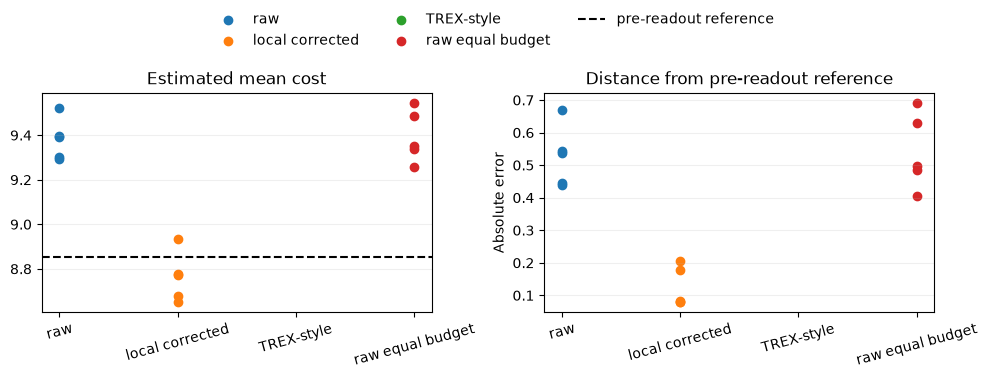

In [7]:
methods = ['raw', 'local corrected', 'TREX-style', 'raw equal budget']
fig, axes = plt.subplots(1, 2, figsize=(10, 3.8))
for index, method in enumerate(methods):
    values = results.loc[results.method == method, 'mean cost']
    axes[0].scatter([index] * len(values), values, label=method)
    if reference_cost is not None:
        axes[1].scatter([index] * len(values), abs(values - reference_cost))
if reference_cost is not None:
    axes[0].axhline(reference_cost, color='black', linestyle='--', label='pre-readout reference')
else:
    axes[1].text(.5, .5, 'Reference skipped', ha='center', transform=axes[1].transAxes)
axes[0].set_title('Estimated mean cost')
axes[1].set_title('Distance from pre-readout reference')
axes[1].set_ylabel('Absolute error')
for ax in axes:
    ax.set_xticks(range(len(methods)), methods, rotation=15)
    ax.grid(axis='y', alpha=.2)
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc='upper center', ncol=3, frameon=False)
fig.tight_layout(rect=(0, 0, 1, .86))
plt.show()

## What did I find?

The exact pre-readout reference is **8.854**. The saved summary table reports **8.761 ± 0.111** for both M3 and local correction, **9.381 ± 0.093** for raw sampling, and **9.396 ± 0.117** for raw sampling at the equal total shot budget. Both corrections moved the mean estimate closer to the reference, but M3 did not improve on local correction in this five-qubit test. The saved result does not demonstrate M3's scaling advantage; results on another backend are deferred.

## References

- [M3: Matrix-free Measurement Mitigation](https://doi.org/10.1103/PRXQuantum.2.040326)
- [Qiskit M3 add-on documentation](https://qiskit.github.io/qiskit-addon-mthree/)
- [M3 readout mitigation guide for Qiskit Sampler](https://qiskit.qotlabs.org/docs/tutorials/readout-error-mitigation-sampler)